# Linear regression and gradient descent

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Anatole-1/exercices-machine-learning/blob/main/01_linear_regression.ipynb)

1. Exercise 1 – Combined Cycle Power Plant: linear regression on scaled features
2. Exercise 2 – Fitting a parabola with gradient descent
3. Exercise 3 – Pump curves (RPM, flow rate → total head)
4. Exercise 4 – Minimising a sum of distances (Steiner points) with gradient descent

Run the notebook from the repository folder (the data files are in `data/`). In Google Colab, the first code cell clones the repository automatically.

In [ ]:
# Google Colab: get the data files by cloning the repository
import os, subprocess
if 'google.colab' in str(get_ipython()) and not os.path.exists('data'):
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/Anatole-1/exercices-machine-learning.git'], check=True)
    os.chdir('exercices-machine-learning')

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
rng=np.random.default_rng() #seed = random

## Exercise 1


[Combined Cycle Power Plant dataset](https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant)



![figure](images/01_ex1_1.png)

![figure](images/01_ex1_2.png)

The data file is `data/Folds5x2_pp.csv`.

In [ ]:
#read the dataset into a matrix data
data=np.loadtxt('data/Folds5x2_pp.csv', delimiter=',', skiprows=1)
X=data[:,:4] #coodinates [x1,x2,x3,x4]=[T,V,AP,RH] as rows
y=data[:,4] #values of PE to be predicted

print(X[:5,:])
print(y[:5])

[[   8.34   40.77 1010.84   90.01]
 [  23.64   58.49 1011.4    74.2 ]
 [  29.74   56.9  1007.15   41.91]
 [  19.07   49.69 1007.22   76.79]
 [  11.8    40.66 1017.13   97.2 ]]
[480.48 445.75 438.76 453.09 464.43]


Draw pictures like below of the distributions of values of the coordinates and $y=PE$

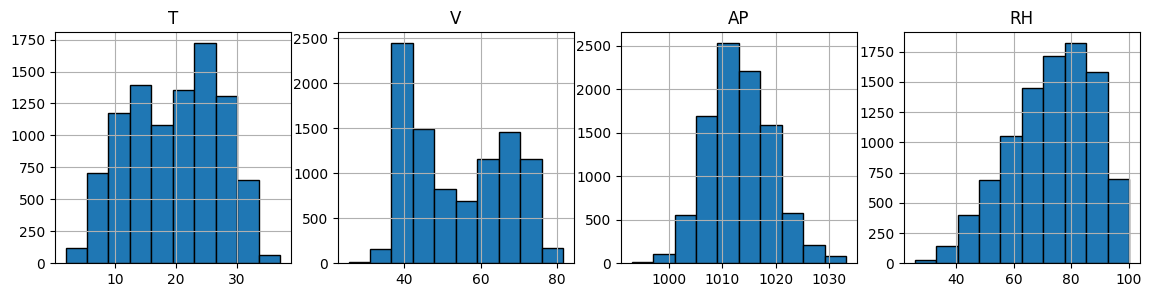

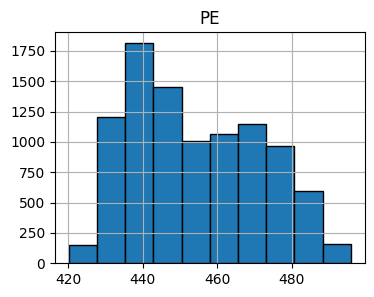

In [ ]:
feature_names = ['T', 'V', 'AP', 'RH']

plt.figure(figsize=(14, 3))
for k in range(4):
    plt.subplot(1, 4, k + 1)
    plt.hist(X[:, k], bins=10, edgecolor='k')
    plt.grid()
    plt.title(feature_names[k])

plt.show()

plt.figure(figsize=(4, 3))
plt.hist(y, bins=10, edgecolor='k')
plt.grid()
plt.title('PE')
plt.show()

![figure](images/01_ex1_3.png)

and on the dependence of $y=PE$ on the coordinates $T,V,AP,RH$

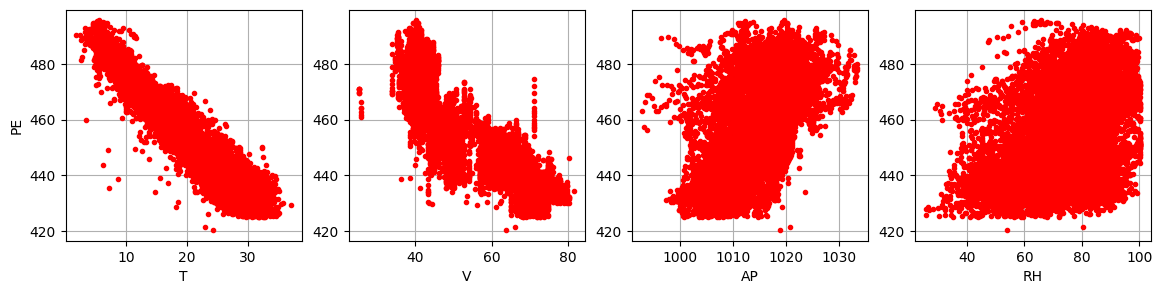

In [ ]:
plt.figure(figsize=(14, 3))

for k in range(4):
    plt.subplot(1, 4, k + 1)
    plt.plot(X[:, k], y, 'r.')
    plt.grid()
    plt.xlabel(feature_names[k])
    if k == 0:
        plt.ylabel('PE')

plt.show()

![figure](images/01_ex1_4.png)

Find coefficients to a formula  
$$
y=w_1\widehat{x}_1+w_2\widehat{x}_2+w_3\widehat{x}_3+w_4\widehat{x}_4+b
$$

using the scaled coordinates

$$
\widehat{x}_j=\frac{x_j-\mu_j}{\sigma_j},\quad j=1,2,3,4
$$



(ans: $w=[-14.737, -2.972,   0.369,  -2.308],\,b=
454.365$)


 and draw a picture like below

![figure](images/01_ex1_5.png)

In [ ]:
mu = np.mean(X, axis=0)
s = np.std(X, axis=0)
Xhat = (X - mu) / s

from sklearn.linear_model import LinearRegression

model_hat = LinearRegression().fit(Xhat, y)

w = model_hat.coef_
b = model_hat.intercept_

np.set_printoptions(precision=3, suppress=True)
print("w =", w)
print("b =", b)

w = [-14.737  -2.972   0.369  -2.308]
b = 454.36500940635386


mse = 20.767397532535018
mae = 3.6252158076011827


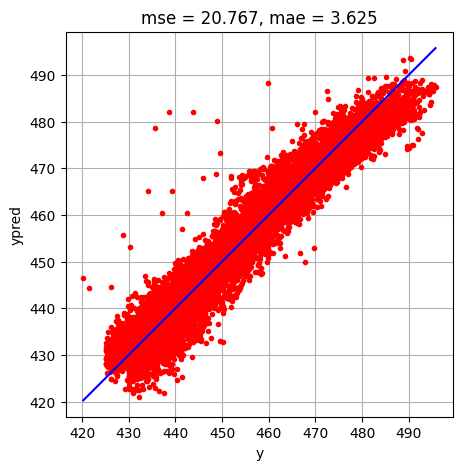

In [ ]:
# predicted values from the fitted formula
ypred = np.sum(w * Xhat, axis=1) + b

m = len(y)
mse = 1/m * np.sum((ypred - y)**2)
mae = 1/m * np.sum(np.abs(ypred - y))

print("mse =", mse)
print("mae =", mae)

ymin = np.min(y)
ymax = np.max(y)

plt.figure(figsize=(5, 5))
plt.plot(y, ypred, 'r.')
plt.plot([ymin, ymax], [ymin, ymax], 'b')
plt.grid()
plt.axis('equal')
plt.xlabel('y')
plt.ylabel('ypred')
plt.title('mse = {:.3f}, mae = {:.3f}'.format(mse, mae))
plt.show()

Calculate the predicted value for $y$, when
$x=[8,40,1050,95]$

(ans: 479.60)

In [ ]:
xt = np.array([8, 40, 1050, 95])

xt_hat = (xt - mu) / s
yt = np.sum(w * xt_hat) + b

print("xt_hat =", xt_hat)
print("predicted y =", yt)

xt_hat = [-1.563 -1.126  6.187  1.486]
predicted y = 479.6044637517668


## Exercise 2


Use the points $x^{(i)},y^{(i)}$ given below to find a formula

$$
y=w_1x^2+w_2x+b
$$

using linear regression for datapoints

$$
[x_1^{(i)},x_2^{(i)}],\,y^{(i)}
$$

where

$$x_1^{(i)}=(x^{(i)})^2,\,x_2^{(i)}=x^{(i)}$$.


Find the coefficients  $w_1,w_2,b$
by minimizing the cost

$$
C=\frac{1}{m}\,\sum_{i=1}^m \left(w_1x^{(i)}_1+w_2x^{(i)}_2+b-y^{(i)}\right)^2
$$


using the gradient descent.

Draw pictures like below.

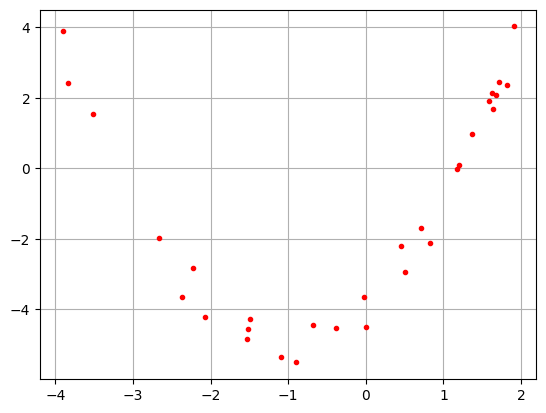

In [ ]:
#points x^(i),y^(i)
m=30 #number of points
A=1
B=2
C=-4
x0=-B/(2*A)
L=3

x=rng.uniform(x0-L,x0+L,m) #uniformly from x0-L...x0+L
error=rng.normal(0,0.4,m)
y=A*x**2+B*x+C+error

plt.plot(x,y,'r.')
plt.grid()
plt.show()

In [ ]:
# transformed variables:
# x1^(i) = (x^(i))^2
# x2^(i) = x^(i)

x1 = x**2
x2 = x

# gradient descent parameters
alfa = 0.01
N = 500

# initial values
w1 = 1.1
w2 = 1.0
b = 1.1

# store the values during updates
W1 = np.zeros(N + 1)
W2 = np.zeros(N + 1)
Bv = np.zeros(N + 1)
Cost = np.zeros(N + 1)

W1[0] = w1
W2[0] = w2
Bv[0] = b
Cost[0] = 1/m * np.sum((w1 * x1 + w2 * x2 + b - y)**2)

for n in range(N):
    ypred = w1 * x1 + w2 * x2 + b

    dCw1 = 1/m * np.sum(2 * (ypred - y) * x1)
    dCw2 = 1/m * np.sum(2 * (ypred - y) * x2)
    dCb  = 1/m * np.sum(2 * (ypred - y))

    w1 = w1 - alfa * dCw1
    w2 = w2 - alfa * dCw2
    b  = b  - alfa * dCb

    W1[n + 1] = w1
    W2[n + 1] = w2
    Bv[n + 1] = b
    Cost[n + 1] = 1/m * np.sum((w1 * x1 + w2 * x2 + b - y)**2)

print("w1 =", w1)
print("w2 =", w2)
print("b =", b)
print("last cost =", Cost[N])

w1 = 0.9918858499153328
w2 = 2.006611240715276
b = -3.8963772703143618
last cost = 0.15338078240286263


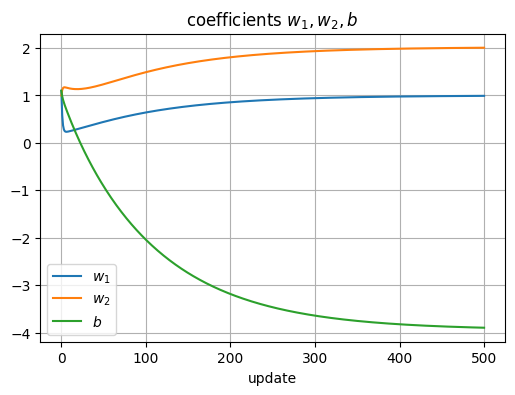

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(W1, label=r'$w_1$')
plt.plot(W2, label=r'$w_2$')
plt.plot(Bv, label=r'$b$')
plt.grid()
plt.xlabel('update')
plt.title(r'coefficients $w_1,w_2,b$')
plt.legend()
plt.show()

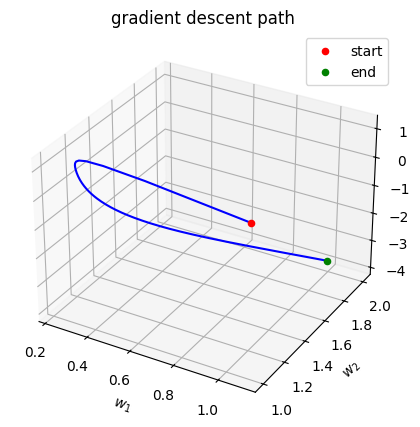

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection='3d')

ax.plot(W1, W2, Bv, 'b')
ax.scatter(W1[0], W2[0], Bv[0], c='r', label='start')
ax.scatter(W1[-1], W2[-1], Bv[-1], c='g', label='end')

ax.set_xlabel(r'$w_1$')
ax.set_ylabel(r'$w_2$')
ax.set_zlabel(r'$b$')
ax.set_title('gradient descent path')
ax.legend()

plt.show()

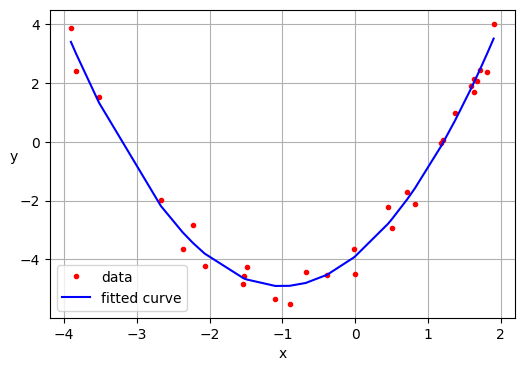

In [ ]:
# sort x for a clean curve
ind = np.argsort(x)
xs = x[ind]
ypreds = w1 * xs**2 + w2 * xs + b

plt.figure(figsize=(6, 4))
plt.plot(x, y, 'r.', label='data')
plt.plot(xs, ypreds, 'b', label='fitted curve')
plt.grid()
plt.xlabel('x')
plt.ylabel('y', rotation=0)
plt.legend()
plt.show()

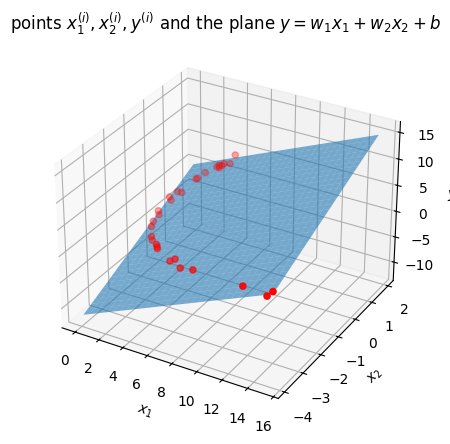

In [ ]:
# 3D picture with transformed coordinates x1=x^2, x2=x and the plane y=w1*x1+w2*x2+b
from mpl_toolkits.mplot3d import Axes3D

x1 = x**2
x2 = x

# grid for the plane
u = np.linspace(np.min(x1), np.max(x1), 30)
v = np.linspace(np.min(x2), np.max(x2), 30)
U, V = np.meshgrid(u, v)
Yplane = w1 * U + w2 * V + b

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(x1, x2, y, c='r')
ax.plot_surface(U, V, Yplane, alpha=0.6)

ax.set_xlabel(r'$x_1$')
ax.set_ylabel(r'$x_2$')
ax.set_zlabel(r'$y$')
ax.set_title(r'points $x_1^{(i)},x_2^{(i)},y^{(i)}$ and the plane $y=w_1x_1+w_2x_2+b$')

plt.show()

![figure](images/01_ex2_1.png)

![figure](images/01_ex2_2.png)

## Exercise 3


![figure](images/01_ex3_1.png)

The data file is `data/data_ex3.txt` (values read from the pump curves above).

In [ ]:
#read data into a matrix data
data=np.loadtxt('data/data_ex3.txt',delimiter=',')
#rows [x1^(i),x2^(i),y^(i)] = [RPM/1000,FLOW RATE/1000,TOTAL HEAD] (taken from the picture above)
data[:5,:]

array([[ 1.48,  0.  , 36.1 ],
       [ 1.48,  0.05, 35.6 ],
       [ 1.48,  0.1 , 35.2 ],
       [ 1.48,  0.15, 34.6 ],
       [ 1.48,  0.2 , 34.4 ]])

In [ ]:
x1 = data[:, 0]
x2 = data[:, 1]
y = data[:, 2]

print(data.shape)

(139, 3)


Use the points $x_1^{(i)},x_2^{(i)},y^{(i)}$ to find a formula

$$
y=w_1x_1^2+w_2x_2^2+w_3x_1+w_4x_2+b
$$


using linear regression for the datapoints

$$
[(x_1^{(i)})^2,(x_2^{(i)})^2,x_1^{(i)},x_2^{(i)}],\quad y^{(i)}
$$

and draw pictures like below:

In [ ]:
# transformed coordinates:
# [(x1^(i))^2, (x2^(i))^2, x1^(i), x2^(i)]

X = np.column_stack((x1**2, x2**2, x1, x2))

from sklearn.linear_model import LinearRegression

model = LinearRegression().fit(X, y)

w1, w2, w3, w4 = model.coef_
b = model.intercept_

np.set_printoptions(precision=3, suppress=True)
print("w1 =", w1)
print("w2 =", w2)
print("w3 =", w3)
print("w4 =", w4)
print("b  =", b)

w1 = 17.83664169260345
w2 = -12.298973768581364
w3 = -3.442523001260108
w4 = -3.9242498637287606
b  = 1.8033396755807445


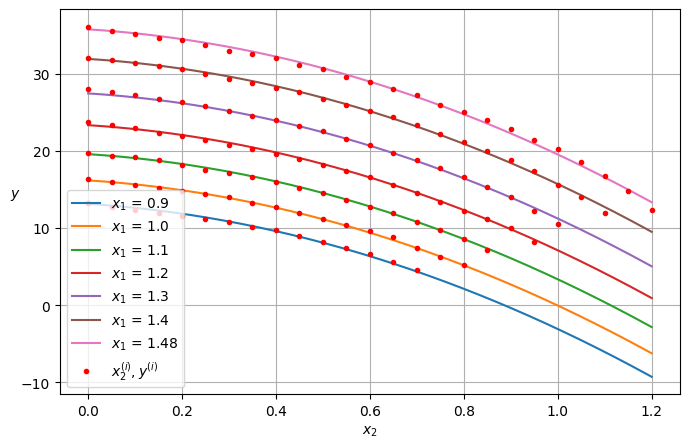

In [ ]:
x1_values = np.unique(x1)
x2line = np.linspace(np.min(x2), np.max(x2), 300)

plt.figure(figsize=(8, 5))

for val in x1_values:
    yline = w1 * val**2 + w2 * x2line**2 + w3 * val + w4 * x2line + b
    plt.plot(x2line, yline, label=fr'$x_1$ = {val}')

plt.plot(x2, y, 'r.', label=r'$x_2^{(i)}, y^{(i)}$')
plt.grid()
plt.xlabel(r'$x_2$')
plt.ylabel(r'$y$', rotation=0)
plt.legend()
plt.show()

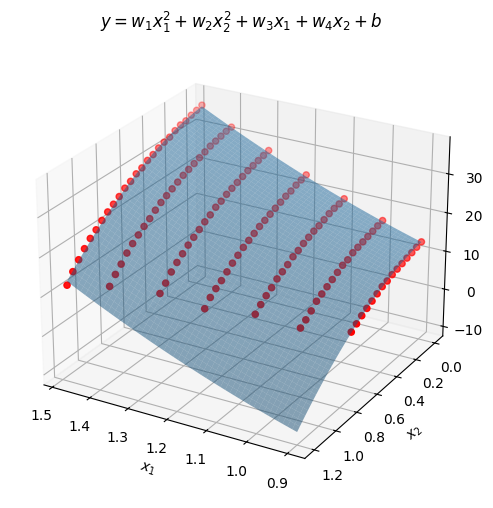

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

# grid for the surface
u = np.linspace(np.min(x1), np.max(x1), 50)
v = np.linspace(np.min(x2), np.max(x2), 50)
U, V = np.meshgrid(u, v)

Ysurf = w1 * U**2 + w2 * V**2 + w3 * U + w4 * V + b

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(U, V, Ysurf, alpha=0.5)
ax.scatter(x1, x2, y, c='r', s=20)

ax.set_xlabel(r'$x_1$')
ax.set_ylabel(r'$x_2$')
ax.set_zlabel(r'$y$')
ax.set_title(r'$y=w_1x_1^2+w_2x_2^2+w_3x_1+w_4x_2+b$')

ax.view_init(elev=25, azim=120)

plt.show()

![figure](images/01_ex3_2.png)

ans: $w_1=17.837,w_2=-12.299,w_3=-3.443,w_4=-3.924,b=1.803$

## Exercise 4


Given the coordinates of points $A,B,C$ and $D$, use gradient descent to find the coordinates of points $S_1=[x_1,y_1]$ and $S_2=[x_2,y_2]$ that minimize  the sum of distances

$$
AS_1+BS_1+S_1S_2+CS_2+DS_2
$$



$$=
\sqrt{(Ax-x_1)^2+(Ay-y_1)^2}+\sqrt{(Bx-x_1)^2+(By-y_1)^2}
$$

$$+\sqrt{(x_1-x_2)^2+(y_1-y_2)^2}
$$

$$+
\sqrt{(Cx-x_2)^2+(Cy-y_2)^2}+
\sqrt{(Dx-x_2)^2+(Dy-y_2)^2}
$$

and draw a picture like below.

In [ ]:
# coordinates of the fixed points
Ax, Ay = 1, 2
Bx, By = 2, 4
Cx, Cy = 4, 0
Dx, Dy = 6, 2

# learning rate and number of updates
alfa = 0.05
N = 500

# initial values for S1=[x1,y1] and S2=[x2,y2]
x1 = 2.0
y1 = 0.0
x2 = 6.0
y2 = 4.0

# collect the values during gradient descent
X1 = np.zeros(N + 1)
Y1 = np.zeros(N + 1)
X2 = np.zeros(N + 1)
Y2 = np.zeros(N + 1)
Cost = np.zeros(N + 1)

X1[0] = x1
Y1[0] = y1
X2[0] = x2
Y2[0] = y2

Cost[0] = (
    np.sqrt((Ax - x1)**2 + (Ay - y1)**2) +
    np.sqrt((Bx - x1)**2 + (By - y1)**2) +
    np.sqrt((x1 - x2)**2 + (y1 - y2)**2) +
    np.sqrt((Cx - x2)**2 + (Cy - y2)**2) +
    np.sqrt((Dx - x2)**2 + (Dy - y2)**2)
)

for n in range(N):
    # distances
    dA = np.sqrt((Ax - x1)**2 + (Ay - y1)**2)
    dB = np.sqrt((Bx - x1)**2 + (By - y1)**2)
    d12 = np.sqrt((x1 - x2)**2 + (y1 - y2)**2)
    dC = np.sqrt((Cx - x2)**2 + (Cy - y2)**2)
    dD = np.sqrt((Dx - x2)**2 + (Dy - y2)**2)

    # partial derivatives of the cost function
    dCx1 = (x1 - Ax)/dA + (x1 - Bx)/dB + (x1 - x2)/d12
    dCy1 = (y1 - Ay)/dA + (y1 - By)/dB + (y1 - y2)/d12
    dCx2 = (x2 - x1)/d12 + (x2 - Cx)/dC + (x2 - Dx)/dD
    dCy2 = (y2 - y1)/d12 + (y2 - Cy)/dC + (y2 - Dy)/dD

    # update
    x1 = x1 - alfa * dCx1
    y1 = y1 - alfa * dCy1
    x2 = x2 - alfa * dCx2
    y2 = y2 - alfa * dCy2

    # collect
    X1[n + 1] = x1
    Y1[n + 1] = y1
    X2[n + 1] = x2
    Y2[n + 1] = y2

    Cost[n + 1] = (
        np.sqrt((Ax - x1)**2 + (Ay - y1)**2) +
        np.sqrt((Bx - x1)**2 + (By - y1)**2) +
        np.sqrt((x1 - x2)**2 + (y1 - y2)**2) +
        np.sqrt((Cx - x2)**2 + (Cy - y2)**2) +
        np.sqrt((Dx - x2)**2 + (Dy - y2)**2)
    )

print("S1 =", [x1, y1])
print("S2 =", [x2, y2])
print("last cost =", Cost[N])

S1 = [np.float64(1.9073024482152663), np.float64(2.4537221928569144)]
S2 = [np.float64(4.061940849257928), np.float64(1.0311401074109046)]
last cost = 8.345119313984984


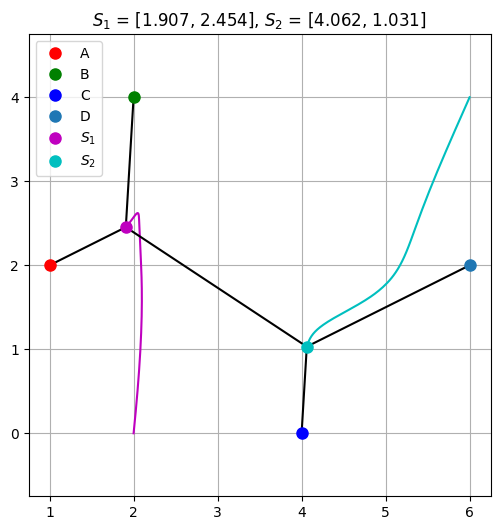

In [ ]:
plt.figure(figsize=(6, 6))

# trajectories of S1 and S2 during gradient descent
plt.plot(X1, Y1, 'm')
plt.plot(X2, Y2, 'c')

# final broken-line network
plt.plot([Ax, x1], [Ay, y1], 'k')
plt.plot([Bx, x1], [By, y1], 'k')
plt.plot([x1, x2], [y1, y2], 'k')
plt.plot([Cx, x2], [Cy, y2], 'k')
plt.plot([Dx, x2], [Dy, y2], 'k')

# points
plt.plot(Ax, Ay, 'ro', markersize=8, label='A')
plt.plot(Bx, By, 'go', markersize=8, label='B')
plt.plot(Cx, Cy, 'bo', markersize=8, label='C')
plt.plot(Dx, Dy, 'o', color='tab:blue', markersize=8, label='D')
plt.plot(x1, y1, 'mo', markersize=8, label=r'$S_1$')
plt.plot(x2, y2, 'o', color='c', markersize=8, label=r'$S_2$')

plt.grid()
plt.xlim(0.75, 6.25)
plt.ylim(-0.75, 4.75)
plt.gca().set_aspect('equal', adjustable='box')

plt.title(r'$S_1$ = [{:.3f}, {:.3f}], $S_2$ = [{:.3f}, {:.3f}]'.format(x1, y1, x2, y2))
plt.legend()
plt.show()

![figure](images/01_ex4_1.png)